# 07 · Pollution along the growth path, by institutions

Successor project, branch `successor/pollution-institutions`. Rules:
[`docs/successors/pollution-institutions-prespec.md`](../../docs/successors/pollution-institutions-prespec.md)
§3–§4 and the change log of 2026-10-29 (terciles compared only on common support). Descriptive only.

ln PM2.5 (region mean of the 10 km panel) on a piecewise-linear spline in ln DOSE output per person
(knots 1,000 / 4,000 / 12,000 USD), interacted with baseline (1998–2000) `v2x_polyarchy` terciles,
with `P_a`, `T_a`, region FE and tercile × year FE, clustered by country.

In [1]:
import sys, warnings
from pathlib import Path
import pandas as pd

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT))
warnings.filterwarnings("ignore")
from src.analysis import pollution as P

s = P.sample(P.build_region_panel())
print(f"{len(s):,} region-years, {s.GID_1.nunique():,} regions, {s.GID_0.nunique()} countries, "
      f"{s.year.min()}-{s.year.max()}")

27,512 region-years, 1,564 regions, 77 countries, 1998-2018


## ◇ G1: coverage (no PM2.5)

Each tercile: ≥ 15 countries, ≥ 150 regions, and ≥ 50 regions with income in each segment.
Recorded outcome: fails on support; the change log keeps only supported cells (≥ 50 regions).

In [2]:
n = P.supported_cells(s)
n.insert(0, "regions", s.groupby("tercile").GID_1.nunique())
n.insert(0, "countries", s.groupby("tercile").GID_0.nunique())
n.columns = ["countries", "regions", *P.SEGMENT_LABELS]
n

,countries,regions,"< 1,000","1,000-4,000","4,000-12,000","> 12,000"
tercile,,,,,,
0.0,26,552,175,441,221,43
1.0,25,597,83,342,346,154
2.0,26,415,0,18,133,344


In [3]:
pd.DataFrame(P.comparisons(P.supported_cells(s)), columns=["segment", "a", "b"])

,segment,a,b
0,seg0,0,1
1,seg1,0,1
2,seg2,0,1
3,seg2,1,2
4,seg3,1,2


## Main specification: country clusters

In [4]:
main = P.fit_paths(s)
print(f"N = {main['n']:,}")
main["slopes"].round(4)

N = 27,512


,segment,group,regions,supported,est,se,p
0,"< 1,000",0,175,True,0.1183,0.0433,0.0078
1,"< 1,000",1,83,True,0.2082,0.1703,0.2251
2,"< 1,000",2,0,False,NaN,NaN,NaN
3,"1,000-4,000",0,441,True,0.0576,0.0228,0.0136
4,"1,000-4,000",1,342,True,0.0633,0.0546,0.2500
5,"1,000-4,000",2,18,False,0.7103,0.0619,0.0000
6,"4,000-12,000",0,221,True,-0.0091,0.0594,0.8793
7,"4,000-12,000",1,346,True,-0.0511,0.0715,0.4769
8,"4,000-12,000",2,133,True,0.1179,0.0779,0.1342
9,"> 12,000",0,43,False,-0.0220,0.0381,0.5658


### ◇ Moderation: the five supported comparisons and their joint Wald test

In [5]:
print(main["wald"])
main["diffs"].round(4)

{'F': 0.8300774651807489, 'q': 5, 'df2': 76, 'p': 0.53229600920971}


,segment,comparison,diff,se,p
0,"< 1,000",1 - 0,0.0899,0.1756,0.6101
1,"1,000-4,000",1 - 0,0.0058,0.0593,0.9228
2,"4,000-12,000",1 - 0,-0.0420,0.0929,0.6522
3,"4,000-12,000",2 - 1,0.1690,0.1064,0.1162
4,"> 12,000",2 - 1,0.0787,0.0740,0.2908


### Information: region clusters

In [6]:
reg = P.fit_paths(s, vcov={"CRV1": "GID_1"})
print(reg["wald"])
pd.concat([reg["slopes"].round(4), reg["diffs"].round(4)], keys=["slopes", "diffs"])

{'F': 6.793675820934759, 'q': 5, 'df2': 76, 'p': 2.7627330418788537e-05}


segment  group  regions supported     est      se       p  \
slopes 0        < 1,000    0.0    175.0      True  0.1183  0.0157  0.0000   
       1        < 1,000    1.0     83.0      True  0.2082  0.0511  0.0000   
       2        < 1,000    2.0      0.0     False     NaN     NaN     NaN   
       3    1,000-4,000    0.0    441.0      True  0.0576  0.0152  0.0002   
       4    1,000-4,000    1.0    342.0      True  0.0633  0.0214  0.0031   
       5    1,000-4,000    2.0     18.0     False  0.7103  0.0710  0.0000   
       6   4,000-12,000    0.0    221.0      True -0.0091  0.0267  0.7342   
       7   4,000-12,000    1.0    346.0      True -0.0511  0.0186  0.0061   
       8   4,000-12,000    2.0    133.0      True  0.1179  0.0267  0.0000   
       9       > 12,000    0.0     43.0     False -0.0220  0.0406  0.5886   
       10      > 12,000    1.0    154.0      True -0.0450  0.0257  0.0805   
       11      > 12,000    2.0    344.0      True  0.0337  0.0227  0.1376   
diffs  0        < 1,000    NaN      NaN       NaN     NaN  0.0534  0.0965   
       1    1,000-4,000    NaN      NaN       NaN     NaN  0.0262  0.8265   
       2   4,000-12,000    NaN      NaN       NaN     NaN  0.0325  0.1999   
       3   4,000-12,000    NaN      NaN       NaN     NaN  0.0326  0.0000   
       4       > 12,000    NaN      NaN       NaN     NaN  0.0343  0.0247   

          comparison    diff  
slopes 0         NaN     NaN  
       1         NaN     NaN  
       2         NaN     NaN  
       3         NaN     NaN  
       4         NaN     NaN  
       5         NaN     NaN  
       6         NaN     NaN  
       7         NaN     NaN  
       8         NaN     NaN  
       9         NaN     NaN  
       10        NaN     NaN  
       11        NaN     NaN  
diffs  0       1 - 0  0.0899  
       1       1 - 0  0.0058  
       2       1 - 0 -0.0420  
       3       2 - 1  0.1690  
       4       2 - 1  0.0787

## Pooled path (one spline, region + year FE, country clusters)

In [7]:
pooled = P.fit_pooled(s)
pooled["slopes"].round(4)

,Estimate,Std. Error,Pr(>|t|)
"< 1,000",0.2047,0.0435,0.0000
"1,000-4,000",0.1743,0.0432,0.0001
"4,000-12,000",0.0512,0.0575,0.3759
"> 12,000",-0.0827,0.0522,0.1169


## Variants 1 and 2 (needed for the moderation rule's sign check)

1. + country-specific linear trends; 2. country × year FE instead of tercile × year FE.

In [8]:
s1, trends = P.add_country_trends(s)
v1 = P.fit_paths(s1, extra=trends)
v2 = P.fit_paths(s, fe="GID_1 + GID_0^year")
for k, r in {"variant 1": v1, "variant 2": v2}.items():
    print(k, r["wald"])
signs = main["diffs"][["segment", "comparison", "diff", "p"]].rename(columns={"diff": "main", "p": "p_main"})
signs["v1"] = v1["diffs"]["diff"].values
signs["p_v1"] = v1["diffs"]["p"].values
signs["v2"] = v2["diffs"]["diff"].values
signs["p_v2"] = v2["diffs"]["p"].values
signs.round(4)

variant 1 {'F': 0.6823311118313466, 'q': 5, 'df2': 76, 'p': 0.6382000632623868}
variant 2 {'F': 0.782076288148059, 'q': 5, 'df2': 76, 'p': 0.5657269333958641}


,segment,comparison,main,p_main,v1,p_v1,v2,p_v2
0,"< 1,000",1 - 0,0.0899,0.6101,0.0095,0.8657,0.0235,0.5986
1,"1,000-4,000",1 - 0,0.0058,0.9228,-0.0352,0.2210,-0.0345,0.2594
2,"4,000-12,000",1 - 0,-0.0420,0.6522,-0.0118,0.7447,-0.0269,0.3373
3,"4,000-12,000",2 - 1,0.1690,0.1162,-0.0705,0.4579,0.0145,0.8217
4,"> 12,000",2 - 1,0.0787,0.2908,0.0268,0.4752,0.0688,0.3043


In [9]:
pd.concat([v1["slopes"].round(4), v2["slopes"].round(4)], keys=["variant 1", "variant 2"])

segment  group  regions  supported     est      se       p
variant 1 0        < 1,000      0      175       True  0.0331  0.0280  0.2413
          1        < 1,000      1       83       True  0.0426  0.0488  0.3861
          2        < 1,000      2        0      False     NaN     NaN     NaN
          3    1,000-4,000      0      441       True -0.0063  0.0246  0.7977
          4    1,000-4,000      1      342       True -0.0415  0.0141  0.0044
          5    1,000-4,000      2       18      False  0.2189  0.0362  0.0000
          6   4,000-12,000      0      221       True -0.0203  0.0242  0.4042
          7   4,000-12,000      1      346       True -0.0321  0.0268  0.2348
          8   4,000-12,000      2      133       True -0.1026  0.0905  0.2603
          9       > 12,000      0       43      False -0.0332  0.0347  0.3409
          10      > 12,000      1      154       True  0.0040  0.0215  0.8516
          11      > 12,000      2      344       True  0.0308  0.0304  0.3133
variant 2 0        < 1,000      0      175       True -0.0039  0.0181  0.8316
          1        < 1,000      1       83       True  0.0196  0.0405  0.6296
          2        < 1,000      2        0      False     NaN     NaN     NaN
          3    1,000-4,000      0      441       True -0.0070  0.0254  0.7850
          4    1,000-4,000      1      342       True -0.0414  0.0169  0.0167
          5    1,000-4,000      2       18      False  0.2427  0.0268  0.0000
          6   4,000-12,000      0      221       True -0.0109  0.0185  0.5602
          7   4,000-12,000      1      346       True -0.0377  0.0203  0.0674
          8   4,000-12,000      2      133       True -0.0233  0.0604  0.7012
          9       > 12,000      0       43      False -0.0243  0.0311  0.4363
          10      > 12,000      1      154       True  0.0077  0.0112  0.4949
          11      > 12,000      2      344       True  0.0764  0.0651  0.2444

## Figure: PM2.5 along the growth path

**a**, Pooled path: PM2.5 relative to 4,000 USD per person (region + year FE, `P_a`, `T_a`), with
a 95 % band (country clusters). Below, the region-years by income. **b**, Paths by baseline
democracy tercile (main specification), each drawn only over its supported segments (≥ 50 regions)
within its 1st–99th income percentile. Below, each tercile's income distribution: 5–95 %
(thin), interquartile range (thick), median (circle). **c**, Segment elasticities in the main
specification and variants 1–2, with 95 % intervals. Cells with fewer than 50 regions are left
out. Dotted lines are the spline knots. Descriptive only.

Saved to `output/figures/pollution/pm25_paths.{pdf,png}`.

INFO:fontTools.subset:maxp pruned


INFO:fontTools.subset:cmap pruned


INFO:fontTools.subset:post pruned


INFO:fontTools.subset:CFF  pruned


INFO:fontTools.subset:PCLT dropped


INFO:fontTools.subset:GPOS pruned


... (68 outputs left out)

INFO:fontTools.subset:CFF  pruned


INFO:fontTools.subset:GPOS pruned


INFO:fontTools.subset:GSUB pruned


INFO:fontTools.subset:name pruned


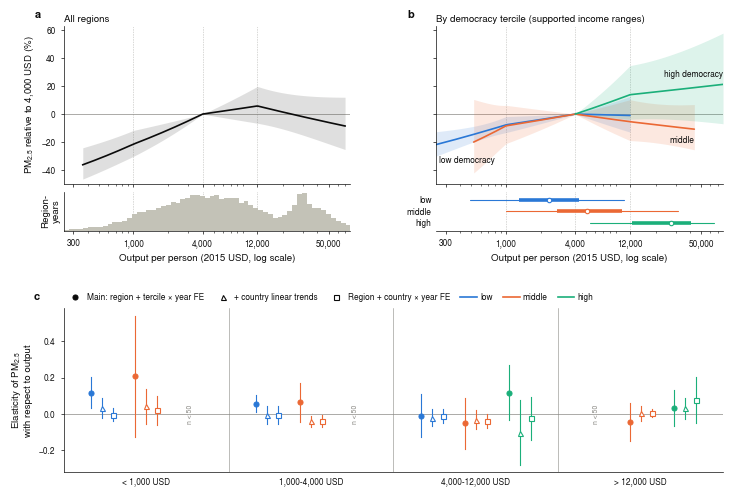

In [10]:
fig = P.plot_paths(s, pooled, main, {"+ country trends": v1, "country × year FE": v2},
                   path=str(PROJECT / P.FIGURES / "pm25_paths"))

## Variants 3–5 (reported, not selected)

Supported cells and comparisons are recomputed for each grouping or sample by the 50-region rule.
3. Rule of law: baseline `v2x_rule` terciles, with rule-of-law tercile × year FE.
4. Without dusty regions: desert share ≤ 0.5.
5. Two separate checks (change log): PM2.5 in levels (µg/m³), and ln PM2.5 weighted by DOSE `pop`
   (region-years without `pop` drop).

In [11]:
rule = P.fit_paths(s, group="tercile_rule")
nodust = P.fit_paths(s[s.desert_share <= 0.5])
levels = P.fit_paths(s, y="pm25")
popw = P.fit_paths(s[s["pop"].gt(0)], weights="pop")
V = {"3 rule of law": rule, "4 desert share <= 0.5": nodust, "5a levels": levels, "5b population weights": popw}
pd.DataFrame([dict(variant=k, N=r["n"], **r["wald"]) for k, r in V.items()]).round(4)

,variant,N,F,q,df2,p
0,3 rule of law,27512,1.1411,5,76,0.3462
1,4 desert share <= 0.5,25749,0.7148,5,76,0.6142
2,5a levels,27512,0.5088,5,76,0.7688
3,5b population weights,26630,9.5654,5,74,0.0000


In [12]:
pd.concat({k: r["diffs"] for k, r in V.items()}).round(4)

segment comparison    diff      se       p
3 rule of law         0       < 1,000      1 - 0  0.0761  0.1257  0.5466
                      1   1,000-4,000      1 - 0  0.0974  0.0747  0.1962
                      2  4,000-12,000      1 - 0  0.0301  0.0988  0.7612
                      3  4,000-12,000      2 - 1  0.1402  0.1272  0.2740
                      4      > 12,000      2 - 1  0.2526  0.1301  0.0559
4 desert share <= 0.5 0       < 1,000      1 - 0  0.1184  0.2044  0.5644
                      1   1,000-4,000      1 - 0 -0.0046  0.0441  0.9176
                      2  4,000-12,000      1 - 0 -0.0501  0.1003  0.6189
                      3  4,000-12,000      2 - 1  0.1642  0.1075  0.1307
                      4      > 12,000      2 - 1  0.0648  0.0755  0.3939
5a levels             0       < 1,000      1 - 0  7.0001  6.1060  0.2552
                      1   1,000-4,000      1 - 0  0.1873  1.7310  0.9141
                      2  4,000-12,000      1 - 0 -2.0097  2.3635  0.3978
                      3  4,000-12,000      2 - 1  1.1337  1.9247  0.5576
                      4      > 12,000      2 - 1  0.9853  1.2397  0.4292
5b population weights 0       < 1,000      1 - 0  0.3632  0.1639  0.0298
                      1   1,000-4,000      1 - 0  0.2051  0.1023  0.0486
                      2  4,000-12,000      1 - 0 -0.2508  0.2051  0.2255
                      3  4,000-12,000      2 - 1  0.5954  0.2719  0.0317
                      4      > 12,000      2 - 1  0.2758  0.2830  0.3329

In [13]:
pd.concat({k: r["slopes"] for k, r in V.items()}).round(4)

segment  group  regions  supported     est  \
3 rule of law         0        < 1,000      0      160       True  0.1253   
                      1        < 1,000      1       98       True  0.2014   
                      2        < 1,000      2        0      False     NaN   
                      3    1,000-4,000      0      478       True  0.0434   
                      4    1,000-4,000      1      319       True  0.1407   
                      5    1,000-4,000      2        4      False  0.5445   
                      6   4,000-12,000      0      231       True -0.0360   
                      7   4,000-12,000      1      379       True -0.0059   
                      8   4,000-12,000      2       90       True  0.1343   
                      9       > 12,000      0       36      False -0.0335   
                      10      > 12,000      1      126       True -0.0043   
                      11      > 12,000      2      379       True  0.2483   
4 desert share <= 0.5 0        < 1,000      0      168       True  0.1143   
                      1        < 1,000      1       69       True  0.2327   
                      2        < 1,000      2        0      False     NaN   
                      3    1,000-4,000      0      387       True  0.0574   
                      4    1,000-4,000      1      322       True  0.0528   
                      5    1,000-4,000      2       18      False  0.7153   
                      6   4,000-12,000      0      183       True  0.0125   
                      7   4,000-12,000      1      331       True -0.0376   
                      8   4,000-12,000      2      133       True  0.1266   
                      9       > 12,000      0       25      False  0.0208   
                      10      > 12,000      1      148       True -0.0365   
                      11      > 12,000      2      336       True  0.0282   
5a levels             0        < 1,000      0      175       True  1.3537   
                      1        < 1,000      1       83       True  8.3538   
                      2        < 1,000      2        0      False     NaN   
                      3    1,000-4,000      0      441       True  1.8001   
                      4    1,000-4,000      1      342       True  1.9874   
                      5    1,000-4,000      2       18      False  7.1846   
                      6   4,000-12,000      0      221       True  0.6300   
                      7   4,000-12,000      1      346       True -1.3796   
                      8   4,000-12,000      2      133       True -0.2460   
                      9       > 12,000      0       43      False -0.9117   
                      10      > 12,000      1      154       True -0.7540   
                      11      > 12,000      2      344       True  0.2313   
5b population weights 0        < 1,000      0      172       True -0.0060   
                      1        < 1,000      1       67       True  0.3572   
                      2        < 1,000      2        0      False     NaN   
                      3    1,000-4,000      0      427       True  0.0531   
                      4    1,000-4,000      1      327       True  0.2582   
                      5    1,000-4,000      2       16      False  0.7393   
                      6   4,000-12,000      0      214       True  0.0002   
                      7   4,000-12,000      1      344       True -0.2505   
                      8   4,000-12,000      2      131       True  0.3448   
                      9       > 12,000      0       36      False  0.0374   
                      10      > 12,000      1      150       True -0.2729   
                      11      > 12,000      2      344       True  0.0029   

                              se       p  
3 rule of law         0   0.0445  0.0062  
                      1   0.1176  0.0909  
                      2      NaN     NaN  
                      3   0.0280  0.1258  
                      4   0.0689  0.0445  

Information for 5b: population weights concentrate on a few countries. Their shares of each
tercile's population-weighted region-years (no PM2.5):

In [14]:
w = s[s["pop"].gt(0)].groupby(["tercile", "GID_0"])["pop"].sum()
(w / w.groupby(level=0).transform("sum")).groupby(level=0, group_keys=False).nlargest(3).round(2)

tercile  GID_0
0.0      CHN      0.62
         IDN      0.10
         RUS      0.06
1.0      IND      0.62
         JPN      0.07
         MEX      0.06
2.0      USA      0.35
         BRA      0.17
         DEU      0.09
Name: pop, dtype: float64

### Figure: variants 3–5

**a**, Paths by baseline rule-of-law tercile (variant 3). **b**, Paths by democracy tercile with
PM2.5 in levels, µg/m³ relative to 4,000 USD (variant 5a). Both are drawn over supported
segments within each group's 1st–99th income percentile, with 95 % bands (country clusters).
Strips below show each group's income distribution. **c**, Segment elasticities in the main
specification, by rule-of-law tercile, without dusty regions and with population weights. Cells
with fewer than 50 regions are left out.

Saved to `output/figures/pollution/pm25_variants.{pdf,png}`.

INFO:fontTools.subset:maxp pruned


INFO:fontTools.subset:cmap pruned


INFO:fontTools.subset:post pruned


INFO:fontTools.subset:CFF  pruned


INFO:fontTools.subset:PCLT dropped


INFO:fontTools.subset:GPOS pruned


... (68 outputs left out)

INFO:fontTools.subset:CFF  pruned


INFO:fontTools.subset:GPOS pruned


INFO:fontTools.subset:GSUB pruned


INFO:fontTools.subset:name pruned


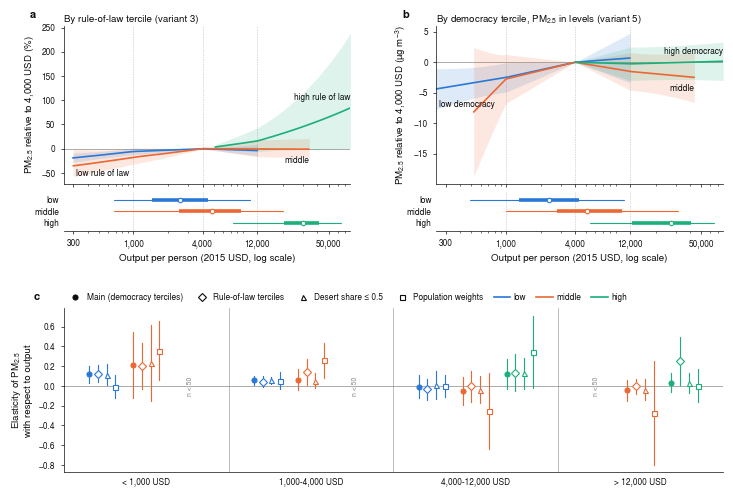

In [15]:
fig = P.plot_robustness(s, main, rule, nodust, popw, levels, path=str(PROJECT / P.FIGURES / "pm25_variants"))

## Variant 6: countries that change tercile (information)

Rules in the change log: yearly `v2x_polyarchy` at the baseline tercile boundaries; a lasting
move (in another tercile every year from the move through 2018, with a move year in 2001–2016).
Movers' regions only: linear slopes before and after the move, by direction, plus a post-move
dummy, region FE and direction × year FE, clustered by country (10 clusters).

In [16]:
v, cuts = P.yearly_terciles(s)
mv = P.movers(v)
print("boundaries:", cuts.round(3))
mv

boundaries: [0.502 0.839]


,GID_0,move_year,base,to,direction
0,ALB,2005,0,1,up
1,BRA,2016,2,1,down
2,GEO,2012,0,1,up
3,HND,2009,1,0,down
4,HUN,2010,2,0,down
5,NGA,2012,0,1,up
6,PER,2001,0,1,up
7,POL,2016,2,1,down
8,THA,2006,1,0,down
9,TUR,2013,1,0,down


In [17]:
mres = P.fit_movers(s, mv)
print(f"N = {mres['n']:,}, countries = {mres['countries']}")
mres["slopes"].round(4)

N = 5,276, countries = 10


,direction,period,est,se,p,countries,regions
0,up,before,-0.1358,0.0408,0.0089,4.0,69.0
1,up,after,-0.0465,0.0398,0.2728,4.0,69.0
2,up,after - before,0.0893,0.0219,0.0028,NaN,NaN
3,down,before,0.0140,0.0506,0.7887,6.0,239.0
4,down,after,-0.0256,0.0496,0.6178,6.0,239.0
5,down,after - before,-0.0396,0.0407,0.3558,NaN,NaN


### Figure: variant 6

**a**, Yearly electoral democracy (V-Dem `v2x_polyarchy`), 1998–2018. Dashed lines are the
baseline tercile boundaries, and the shaded band is the baseline period. Lasting movers are in
colour, with the move year circled. **b**, Movers' elasticities of PM2.5 with respect to output
before (open) and after (filled) the move, with 95 % intervals (country clusters, 10 countries).

Saved to `output/figures/pollution/pm25_movers.{pdf,png}`.

INFO:fontTools.subset:maxp pruned


INFO:fontTools.subset:cmap pruned


INFO:fontTools.subset:post pruned


INFO:fontTools.subset:CFF  pruned


INFO:fontTools.subset:PCLT dropped


INFO:fontTools.subset:GPOS pruned


... (68 outputs left out)

INFO:fontTools.subset:CFF  pruned


INFO:fontTools.subset:GPOS pruned


INFO:fontTools.subset:GSUB pruned


INFO:fontTools.subset:name pruned


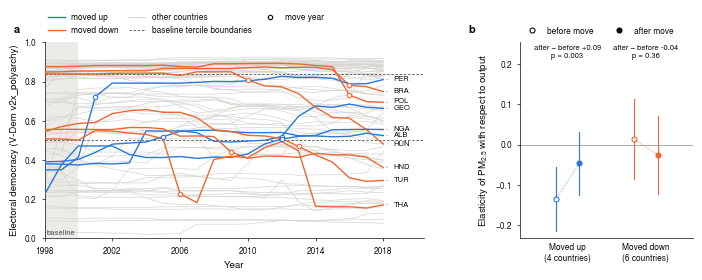

In [18]:
fig = P.plot_movers(v, cuts, mv, mres, path=str(PROJECT / P.FIGURES / "pm25_movers"))

## Summary

Descriptive throughout: paths conditional on region FE, not effects of growth or institutions.
Sample: 1,564 DOSE regions in 77 countries, 1998–2018.

**1. PM2.5 rises with output in poorer regions and flattens in richer ones. No downturn shows.**
In the pooled path, the elasticity is about 0.2 below 4,000 USD per person: going from 1,000 to
4,000 USD comes with about 27 % more PM2.5. Above 4,000 USD the path is flat. It is +6 % at
12,000 USD and −8 % near 60,000 USD, and neither differs from zero. No slope is negative at 5 %
in any specification, so by the pre-specified rule this is flattening, not an environmental
Kuznets turning point.

**2. Where the democracy terciles overlap in income, their paths do not differ.** The joint test
of the five supported comparisons gives p = 0.53. The result holds with country trends
(p = 0.64), country × year FE (0.57), rule of law instead of democracy (0.35), without desert
regions (0.61) and in levels (0.77). By the ◇ rule: **no robust difference between institution
groups.**

**3. The question can only be asked on a narrow overlap.** In DOSE, strong democracies are
never poor and weak ones are rarely rich (G1). No high-democracy region is below 1,000 USD, and
only 43 low-democracy regions are above 12,000 USD. All three terciles overlap only at
4,000–12,000 USD. So the data cannot say whether democracies would have taken a different path
at low incomes, or autocracies at high ones. Within the overlap, income and institutions are
still partly entangled.

**4. The rise is a country-level pattern, not a regional one.** With country × year FE, comparing
regions of the same country in the same year, no supported slope is positive at 5 %. Regions
that grow faster than their country are not more polluted. Two possible reasons, not tested:
PM2.5 travels across regional borders, and the main drivers, such as the energy mix, fuel
standards and national growth, act at country level.

**5. Population weighting changes the answer, but not about institutions.** Weighted by
population, the test rejects (p < 0.001). The weights put 62 % of the low tercile on China,
62 % of the middle on India and 35 % of the high on the United States. So this check compares
mostly those three countries. It is reported, not selected, and does not enter the rule.

**6. Countries that change tercile are too few to read.** Ten countries made a lasting move.
For the four that moved up, the slope rises towards zero after the move (+0.09). For the six
that moved down, it barely changes (−0.04, p = 0.36). With 10 clusters, neither is reliable.

**Bottom line.** On DOSE regions, PM2.5 rises with income up to about 4,000 USD and then
flattens. Where the comparison is possible, baseline democracy and rule of law show no robust
difference in that path. The answer is limited by how little strong institutions and poverty
overlap in the data.

**Caveats.** The outcome is area-weighted, not population-weighted: the pipeline has no
population grid. It includes dust, because ACAG V6GL02.04 has no dust-free series; the desert
check addresses this only in part. DOSE leans towards richer countries (77 here). Institutions
are fixed at their 1998–2000 level. A population-weighted exposure measure and wider coverage of
poor democracies would be needed to ask the question at low incomes.